# Projeto Final - EDA LEGO (Rebrickable)
PUC-SP - Especialização em IA - Big Data e Data Engineering

Grupo:
- Douglas Esteves
- Ricardo Calvoso
- Thiago Americo
- Vitor Gregory

Dados: catálogo da Rebrickable (https://rebrickable.com/downloads/), que tem todos os sets, peças, cores e minifigs da lego em várias tabelas relacionadas.

## 1. ASK - Perguntas

Perguntas que a gente quer responder:

1. Quantos sets são lançados por ano?
2. Os sets ficaram mais complexos (mais peças) com o tempo?
3. Quais temas tem os sets maiores?
4. Quais as cores mais usadas? A lego usa mais cores hoje do que antes?
5. Cada tema tem cores "características"? (ex: Friends rosa, Star Wars cinza)
6. Quais categorias de peças são mais usadas? E as minifigs, aumentaram por set?
7. Dá pra descobrir o tema de um set só olhando as cores e peças dele? (machine learning)

## 2. GET - Carregando os dados

### Baixando os arquivos

Os arquivos vem compactados (.csv.gz) direto do site da rebrickable. Usamos o wget do linux pra baixar.

In [1]:
# !pip install pyspark

In [2]:
tabelas = ['themes', 'colors', 'part_categories', 'parts', 'sets',
           'inventories', 'inventory_parts', 'inventory_minifigs', 'minifigs']

for t in tabelas:
    !wget -q -nc https://cdn.rebrickable.com/media/downloads/{t}.csv.gz

!ls -lh *.csv.gz

-rw-r--r-- 1 root root 4.8K Oct 16 17:11 colors.csv.gz
-rw-r--r-- 1 root root 265K Oct 16 17:11 inventories.csv.gz
-rw-r--r-- 1 root root  99K Oct 16 17:11 inventory_minifigs.csv.gz
-rw-r--r-- 1 root root  14M Oct 16 17:11 inventory_parts.csv.gz
-rw-r--r-- 1 root root 300K Oct 16 17:11 minifigs.csv.gz
-rw-r--r-- 1 root root  856 Oct 16 17:11 part_categories.csv.gz
-rw-r--r-- 1 root root 1.1M Oct 16 17:11 parts.csv.gz
-rw-r--r-- 1 root root 518K Oct 16 17:11 sets.csv.gz
-rw-r--r-- 1 root root 4.5K Oct 16 17:11 themes.csv.gz


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import csv

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

import warnings
warnings.filterwarnings('ignore')

In [4]:
spark = SparkSession.builder.appName('lego_rebrickable').master('local[*]').config('spark.driver.memory', '4g').getOrCreate()
sc = spark.sparkContext
sc.setLogLevel('ERROR')
spark

### RDD

O spark consegue ler o .gz direto, sem precisar descompactar.

Primeiro com a tabela de sets. Usei o csv.reader porque tem nome de set com vírgula dentro das aspas e o split(',') quebrava as colunas.

In [5]:
rdd_sets = sc.textFile('sets.csv.gz')
print(rdd_sets.count())
rdd_sets.take(3)

28544


['set_num,name,year,theme_id,num_parts,img_url',
 '0003977811-1,Ninjago: Book of Adventures,2022,761,1,https://cdn.rebrickable.com/media/sets/0003977811-1.jpg',
 '001-1,Gears,1965,756,43,https://cdn.rebrickable.com/media/sets/001-1.jpg']

In [6]:
header = rdd_sets.first()
sets_rdd = rdd_sets.filter(lambda x: x != header).mapPartitions(lambda linhas: csv.reader(linhas))
# colunas: set_num, name, year, theme_id, num_parts, img_url
sets_rdd.take(2)

[['0003977811-1',
  'Ninjago: Book of Adventures',
  '2022',
  '761',
  '1',
  'https://cdn.rebrickable.com/media/sets/0003977811-1.jpg'],
 ['001-1',
  'Gears',
  '1965',
  '756',
  '43',
  'https://cdn.rebrickable.com/media/sets/001-1.jpg']]

In [7]:
# sets por decada (map + reduceByKey)
por_decada = (sets_rdd
    .map(lambda x: (int(x[2]) // 10 * 10, 1))
    .reduceByKey(lambda a, b: a + b)
    .sortByKey())
por_decada.collect()

[(1940, 5),
 (1950, 175),
 (1960, 445),
 (1970, 663),
 (1980, 1272),
 (1990, 2222),
 (2000, 4841),
 (2010, 9289),
 (2020, 9631)]

In [8]:
# media de peças por decada, so sets com peça > 0
media_decada = (sets_rdd
    .filter(lambda x: int(x[4]) > 0)
    .map(lambda x: (int(x[2]) // 10 * 10, (int(x[4]), 1)))
    .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
    .mapValues(lambda v: round(v[0] / v[1], 1))
    .sortByKey())
media_decada.collect()

[(1940, 96.6),
 (1950, 18.7),
 (1960, 76.1),
 (1970, 107.4),
 (1980, 92.4),
 (1990, 125.7),
 (2000, 176.3),
 (2010, 218.7),
 (2020, 388.3)]

Agora a tabela grande, inventory_parts (mais de 1,5 milhão de linhas). Vamos somar a quantidade de peças por cor usando RDD e depois fazer um **join de RDDs** com a tabela de cores pra pegar o nome.

In [9]:
rdd_ip = sc.textFile('inventory_parts.csv.gz')
h_ip = rdd_ip.first()
ip_rdd = rdd_ip.filter(lambda x: x != h_ip).mapPartitions(lambda l: csv.reader(l))
# colunas: inventory_id, part_num, color_id, quantity, is_spare, img_url
print('linhas:', ip_rdd.count())
print('particoes:', ip_rdd.getNumPartitions())

linhas: 1567180
particoes: 1


Só tem 1 partição! Pesquisei e é porque arquivo .gz não dá pra dividir, então o spark lê tudo numa partição só. Fiz um repartition pra distribuir.

In [10]:
ip_rdd = ip_rdd.repartition(8)

qtd_por_cor = (ip_rdd
    .filter(lambda x: x[4] == 'False')          # tirando as peças reserva (spare)
    .map(lambda x: (x[2], int(x[3])))
    .reduceByKey(lambda a, b: a + b))

rdd_cores = sc.textFile('colors.csv.gz')
h_c = rdd_cores.first()
cores_rdd = rdd_cores.filter(lambda x: x != h_c).mapPartitions(lambda l: csv.reader(l)).map(lambda x: (x[0], x[1]))

# join de RDD: (color_id, (quantidade, nome))
top_cores_rdd = qtd_por_cor.join(cores_rdd).map(lambda x: (x[1][1], x[1][0])).takeOrdered(10, key=lambda x: -x[1])
for nome, qtd in top_cores_rdd:
    print(f'{nome:20s} {qtd:,}')

Black                941,343
Light Bluish Gray    592,069
White                563,556
Dark Bluish Gray     423,061
Red                  352,520
Blue                 231,429
Yellow               231,351
Tan                  220,349
Reddish Brown        200,574
Light Gray           104,966


O que deu pra ver só com RDD:
- a quantidade de sets por década explodiu: 175 nos anos 50, 1.272 nos 80 e 9.289 nos anos 2010 (os anos 2020 ainda nem acabaram e já tem 9.631)
- a média de peças por set também subiu bastante, de uns 92 nos anos 80 pra 388 nos anos 2020
- a cor mais usada de longe é o **preto** (941 mil peças), depois os cinzas e o branco

Fazer com RDD funciona mas dá bem mais trabalho (tratar cabeçalho, aspas, tipo...), então daqui pra frente vou usar DataFrame e SQL.

### DataFrames

Agora carregando todas as tabelas como DataFrame e criando as views pro Spark SQL.

In [11]:
dfs = {}
for t in tabelas:
    dfs[t] = spark.read.csv(f'{t}.csv.gz', header=True, inferSchema=True, quote='"', escape='"')
    dfs[t].createOrReplaceTempView(t)
    print(t, dfs[t].count(), 'linhas')

themes 496 linhas


colors 275 linhas


part_categories 76 linhas


parts 64898 linhas


sets 28543 linhas


inventories 47788 linhas


inventory_parts 1567180 linhas


inventory_minifigs 25903 linhas


minifigs 17293 linhas


In [12]:
dfs['sets'].printSchema()
dfs['sets'].show(5)

root
 |-- set_num: string (nullable = true)
 |-- name: string (nullable = true)
 |-- year: integer (nullable = true)
 |-- theme_id: integer (nullable = true)
 |-- num_parts: integer (nullable = true)
 |-- img_url: string (nullable = true)



+------------+--------------------+----+--------+---------+--------------------+
|     set_num|                name|year|theme_id|num_parts|             img_url|
+------------+--------------------+----+--------+---------+--------------------+
|0003977811-1|Ninjago: Book of ...|2022|     761|        1|https://cdn.rebri...|
|       001-1|               Gears|1965|     756|       43|https://cdn.rebri...|
|      0011-2|   Town Mini-Figures|1979|      67|       12|https://cdn.rebri...|
|      0011-3|Castle 2 for 1 Bo...|1987|     199|        0|https://cdn.rebri...|
|      0012-1|  Space Mini-Figures|1979|     143|       12|https://cdn.rebri...|
+------------+--------------------+----+--------+---------+--------------------+
only showing top 5 rows


In [13]:
dfs['inventory_parts'].show(5)

+------------+--------------+--------+--------+--------+--------------------+
|inventory_id|      part_num|color_id|quantity|is_spare|             img_url|
+------------+--------------+--------+--------+--------+--------------------+
|           1|      48379c04|      72|       1|   false|https://cdn.rebri...|
|           1|         48391|       0|       1|   false|https://cdn.rebri...|
|           1|         48395|       7|       1|   false|https://cdn.rebri...|
|           1|      48864c01|      25|       1|   false|                NULL|
|           1|stickerupn0077|    9999|       1|   false|                NULL|
+------------+--------------+--------+--------+--------+--------------------+
only showing top 5 rows


### Qualidade dos dados

In [14]:
# nulos por tabela
for t in tabelas:
    df = dfs[t]
    nulos = df.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in df.columns]).collect()[0].asDict()
    nulos = {k: v for k, v in nulos.items() if v > 0}
    print(t, nulos)

themes {'parent_id': 150}


colors {'y1': 2, 'y2': 2}
part_categories {}


parts {}


sets {}


inventories {}


inventory_parts {'img_url': 7204}
inventory_minifigs {}


minifigs {}


In [15]:
spark.sql('''
select count(*) as total,
       sum(case when num_parts = 0 then 1 else 0 end) as sets_sem_pecas,
       min(year), max(year)
from sets
''').show()

+-----+--------------+---------+---------+
|total|sets_sem_pecas|min(year)|max(year)|
+-----+--------------+---------+---------+
|28543|          8386|     1949|     2027|
+-----+--------------+---------+---------+



In [16]:
spark.sql('select year, count(*) from sets where year >= 2024 group by year order by year').show()

+----+--------+
|year|count(1)|
+----+--------+
|2024|    1304|
|2025|    1436|
|2026|    1555|
|2027|      57|
+----+--------+



In [17]:
# um set pode ter mais de uma versão de inventario
spark.sql('select version, count(*) from inventories group by version order by version').show(5)

# inventarios de minifig (set_num comeca com fig-)
spark.sql("""select count(*) from inventories where set_num like 'fig-%'""").show()

+-------+--------+
|version|count(1)|
+-------+--------+
|      1|   45834|
|      2|    1288|
|      3|     228|
|      4|     161|
|      5|     112|
+-------+--------+
only showing top 5 rows


+--------+
|count(1)|
+--------+
|   17293|
+--------+



In [18]:
# id duplicado?
print('sets duplicados:', dfs['sets'].count() - dfs['sets'].select('set_num').distinct().count())
print('cores duplicadas:', dfs['colors'].count() - dfs['colors'].select('id').distinct().count())

sets duplicados: 0


cores duplicadas: 0


Sobre a qualidade dos dados:
- quase não tem nulo. Os 150 nulos do `parent_id` em themes são normais, são os temas "raiz" que não tem pai
- não tem set nem cor duplicada
- **8.386 sets (29%) tem 0 peças**. Olhando por cima são livros, chaveiros, roupas etc (o tema Gear e Books)
- tem sets até 2027, mas 2027 só tem 57 (são lançamentos anunciados), então vou cortar 2027
- alguns sets tem mais de uma versão de inventário, vou usar só a versão 1
- 17 mil inventários são de minifigs (set_num começa com fig-), eles somem no join com sets

### Temas: achando o tema "pai"

A tabela themes tem hierarquia (parent_id). Ex: um subtema de Star Wars aponta pro Star Wars. Verificamos que tem no máximo 2 níveis acima, então dá pra resolver com 2 self joins.

In [19]:
temas_raiz = spark.sql('''
select t.id as theme_id, t.name as tema,
       coalesce(avo.name, pai.name, t.name) as tema_raiz
from themes t
left join themes pai on t.parent_id = pai.id
left join themes avo on pai.parent_id = avo.id
''')
temas_raiz.createOrReplaceTempView('temas_raiz')
temas_raiz.show(8)

+--------+---------------+---------+
|theme_id|           tema|tema_raiz|
+--------+---------------+---------+
|       1|        Technic|  Technic|
|       3|    Competition|  Technic|
|       4| Expert Builder|  Technic|
|      16|     RoboRiders|  Technic|
|      17| Speed Slammers|  Technic|
|      18|      Star Wars|  Technic|
|      19|   Supplemental|  Technic|
|      20|Throwbot Slizer|  Technic|
+--------+---------------+---------+
only showing top 8 rows


### ETL - tabela "wide" e parquet

Juntando as tabelas numa tabela grande só (wide), uma linha por peça de cada set, com cor, categoria e tema. Assim fica mais fácil pras análises.

sets → inventories → inventory_parts → colors / parts → part_categories

In [20]:
sets_tema = spark.sql('''
select s.set_num, s.name, s.year, s.num_parts, s.theme_id, tr.tema, tr.tema_raiz
from sets s
join temas_raiz tr on s.theme_id = tr.theme_id
where s.year <= 2026
''')
sets_tema.createOrReplaceTempView('sets_tema')

wide = spark.sql('''
select st.set_num, st.year, st.tema_raiz, st.num_parts,
       ip.part_num, ip.quantity,
       c.name as cor, c.rgb, c.is_trans,
       pc.name as categoria
from sets_tema st
join inventories i on st.set_num = i.set_num and i.version = 1
join inventory_parts ip on ip.inventory_id = i.id
join colors c on ip.color_id = c.id
join parts p on ip.part_num = p.part_num
join part_categories pc on p.part_cat_id = pc.id
where ip.is_spare = false
''')

wide.write.mode('overwrite').parquet('lego_wide.parquet')
sets_tema.write.mode('overwrite').parquet('sets_tema.parquet')
!du -sh lego_wide.parquet sets_tema.parquet inventory_parts.csv.gz

6.5M	lego_wide.parquet
608K	sets_tema.parquet
14M	inventory_parts.csv.gz


In [21]:
wide = spark.read.parquet('lego_wide.parquet')
wide.createOrReplaceTempView('wide')
sets_tema = spark.read.parquet('sets_tema.parquet')
sets_tema.createOrReplaceTempView('sets_tema')
print(wide.count(), 'linhas na tabela wide')
wide.show(5)

1251208 linhas na tabela wide


+--------+----+---------+---------+--------+--------+----------+------+--------+--------------------+
| set_num|year|tema_raiz|num_parts|part_num|quantity|       cor|   rgb|is_trans|           categoria|
+--------+----+---------+---------+--------+--------+----------+------+--------+--------------------+
|TSUPER-1|1991|  Technic|      263|    4589|       1|Light Gray|9BA19D|   false|Bricks Round and ...|
|TSUPER-1|1991|  Technic|      263|    4519|       4|     Black|05131D|   false|       Technic Axles|
|TSUPER-1|1991|  Technic|      263|    4442|       3|     Black|05131D|   false|     Technic Special|
|TSUPER-1|1991|  Technic|      263|   4276b|       1|      Blue|0055BF|   false|Hinges, Arms and ...|
|TSUPER-1|1991|  Technic|      263|   4275b|       1|      Blue|0055BF|   false|Hinges, Arms and ...|
+--------+----+---------+---------+--------+--------+----------+------+--------+--------------------+
only showing top 5 rows


Obs: usei só a versão 1 do inventário pra não contar peça duplicada, tirei as peças reserva (is_spare) e cortei 2027 porque só tem uns 50 sets anunciados.

## 3. EXPLORE

### Q1 - Sets por ano

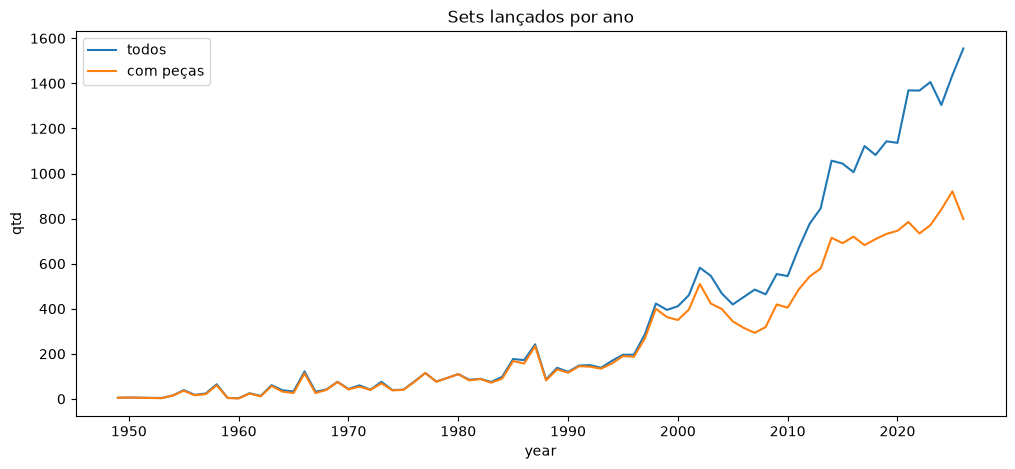

In [22]:
por_ano = spark.sql('''
select year, count(*) as qtd,
       sum(case when num_parts > 0 then 1 else 0 end) as qtd_com_pecas
from sets_tema
group by year order by year
''').toPandas()

plt.figure(figsize=(12,5))
sns.lineplot(data=por_ano, x='year', y='qtd', label='todos')
sns.lineplot(data=por_ano, x='year', y='qtd_com_pecas', label='com peças')
plt.title('Sets lançados por ano')
plt.show()

In [23]:
print(por_ano[por_ano.year.isin([1960, 1970, 1980, 1990, 2000, 2010, 2020, 2025, 2026])])

    year   qtd  qtd_com_pecas
9   1960     3              2
19  1970    44             42
29  1980   110            110
39  1990   120            116
49  2000   411            350
59  2010   545            405
69  2020  1136            746
74  2025  1436            921
75  2026  1555            798


In [24]:
# temas raiz com mais sets
spark.sql('''
select tema_raiz, count(*) as qtd
from sets_tema
group by tema_raiz order by qtd desc limit 12
''').show()

+--------------------+----+
|           tema_raiz| qtd|
+--------------------+----+
|                Gear|6529|
|               Duplo|1464|
|               Books|1453|
|Educational and D...|1128|
|           Star Wars|1103|
|                City|1020|
|Collectible Minif...|1005|
|             Friends| 683|
|             Ninjago| 680|
|                Town| 679|
|             Creator| 637|
|             Technic| 618|
+--------------------+----+



O número de sets lançados por ano cresceu muito: eram 110 em 1980, 411 em 2000 e **1.555 em 2026** (e o ano nem terminou). Dá pra ver uns degraus no gráfico, principalmente depois de 1998 e depois de 2010.

A diferença entre a linha "todos" e "com peças" foi aumentando, porque a lego começou a lançar muita coisa que não é de montar (Gear e Books). Gear é o "tema" com mais itens de todos (6.529).

Dos temas de montar, os que mais tem sets são Duplo, Star Wars e City.

### Q2 - Complexidade dos sets

A partir daqui uso só sets com peças (num_parts > 0) e tiro Gear e Books (que são chaveiro, livro etc).

In [25]:
montaveis = spark.sql('''
select * from sets_tema
where num_parts > 0 and tema_raiz not in ('Gear', 'Books')
''')
montaveis.createOrReplaceTempView('montaveis')

pecas = montaveis.select('set_num', 'name', 'year', 'tema_raiz', 'num_parts').toPandas()
pecas['num_parts'].describe()

count    19009.000000
mean       245.437161
std        523.066020
min          1.000000
25%         22.000000
50%         66.000000
75%        249.000000
max      11695.000000
Name: num_parts, dtype: float64

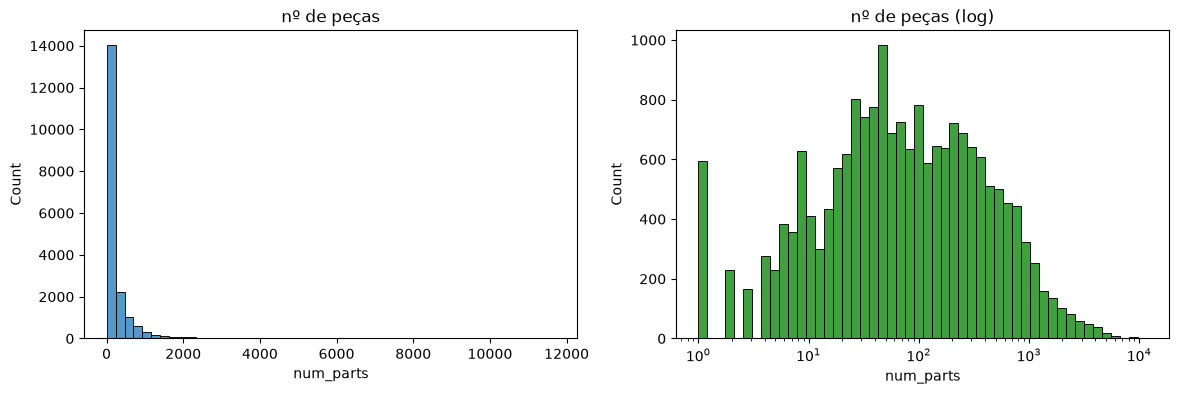

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(14,4))
sns.histplot(pecas['num_parts'], bins=50, ax=ax[0])
ax[0].set_title('nº de peças')
sns.histplot(pecas['num_parts'], bins=50, log_scale=True, ax=ax[1], color='green')
ax[1].set_title('nº de peças (log)')
plt.show()

In [27]:
q1, q3 = np.percentile(pecas['num_parts'], [25, 75])
limite = q3 + 1.5 * (q3 - q1)
print('mediana:', pecas['num_parts'].median(), ' media:', round(pecas['num_parts'].mean(), 1))
print('limite outlier (IQR):', limite)
print('outliers:', (pecas['num_parts'] > limite).sum(), 'de', len(pecas))

mediana: 66.0  media: 245.4
limite outlier (IQR): 589.5
outliers: 2110 de 19009


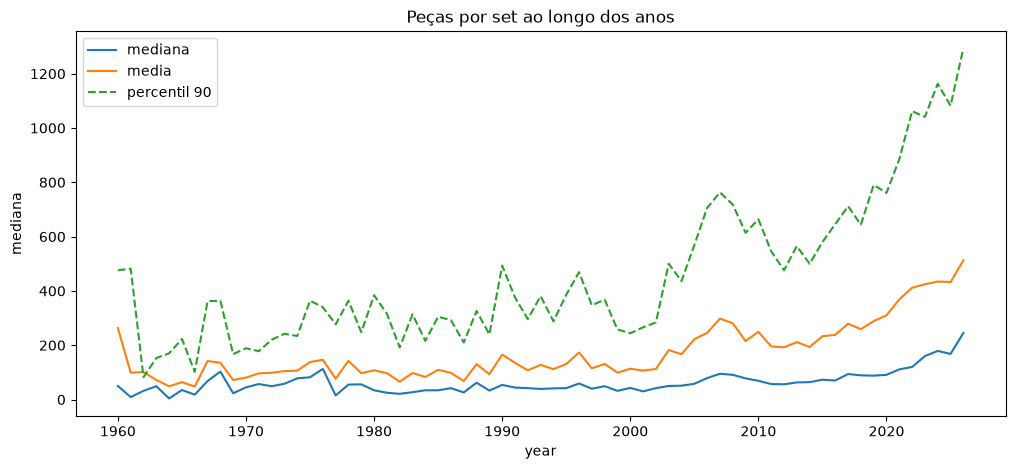

In [28]:
complex_ano = spark.sql('''
select year, percentile_approx(num_parts, 0.5) as mediana, avg(num_parts) as media,
       percentile_approx(num_parts, 0.9) as p90
from montaveis
where year >= 1960
group by year order by year
''').toPandas()

plt.figure(figsize=(12,5))
sns.lineplot(data=complex_ano, x='year', y='mediana', label='mediana')
sns.lineplot(data=complex_ano, x='year', y='media', label='media')
sns.lineplot(data=complex_ano, x='year', y='p90', label='percentil 90', linestyle='--')
plt.title('Peças por set ao longo dos anos')
plt.show()

In [29]:
d = complex_ano[complex_ano.year >= 1990]
coef = np.polyfit(d['year'], d['mediana'], 1)
print('aumento da mediana por ano (desde 1990):', round(coef[0], 2))
print('correlação ano x mediana:', round(np.corrcoef(d['year'], d['mediana'])[0][1], 3))
complex_ano[complex_ano.year.isin([1980, 1990, 2000, 2010, 2015, 2020, 2025, 2026])]

aumento da mediana por ano (desde 1990): 3.35
correlação ano x mediana: 0.783


,year,mediana,media,p90
20,1980,34,107.527778,384
30,1990,54,165.382609,493
40,2000,43,113.518182,244
50,2010,69,249.563158,664
55,2015,73,233.087912,580
60,2020,91,310.158358,761
65,2025,168,432.724419,1082
66,2026,245,512.356307,1293


A distribuição de peças é bem assimétrica: mediana de 66 peças e média de 245. Pelo IQR tudo acima de ~590 peças seria outlier (11% dos sets), mas não vou tirar porque são sets de verdade, só uso a mediana.

**Sim, os sets ficaram maiores!**
- a mediana ficou quase parada entre 1980 e 2000 (uns 35 a 55 peças)
- depois foi subindo: 69 em 2010, 91 em 2020
- e nos últimos anos acelerou muito: **168 em 2025 e 245 em 2026**
- o percentil 90 (sets grandes) passou de 1.200 peças em 2026

Desde 1990 a mediana sobe em média uns 3,4 peças por ano (correlação de 0,78 com o ano), mas a reta não pega bem porque o aumento foi muito mais forte depois de 2020.

### Q3 - Temas com sets maiores

In [30]:
temas_pecas = spark.sql('''
select tema_raiz, count(*) as qtd, percentile_approx(num_parts, 0.5) as mediana, max(num_parts) as maior
from montaveis
group by tema_raiz
having count(*) >= 50
order by mediana desc
''').toPandas()
temas_pecas.head(12)

,tema_raiz,qtd,mediana,maior
0,BrickLink Designer Program,63,2196,4086
1,Icons,88,1420,10001
2,LEGO Ideas and CUUSOO,105,962,4712
3,FIRST LEGO League,61,779,2179
4,Monkie Kid,58,757,2438
5,Architecture,65,565,4382
6,Make & Create,107,480,2000
7,Classic,77,450,1800
8,LEGO Exclusive,80,407,1912
9,Botanicals,51,372,1173


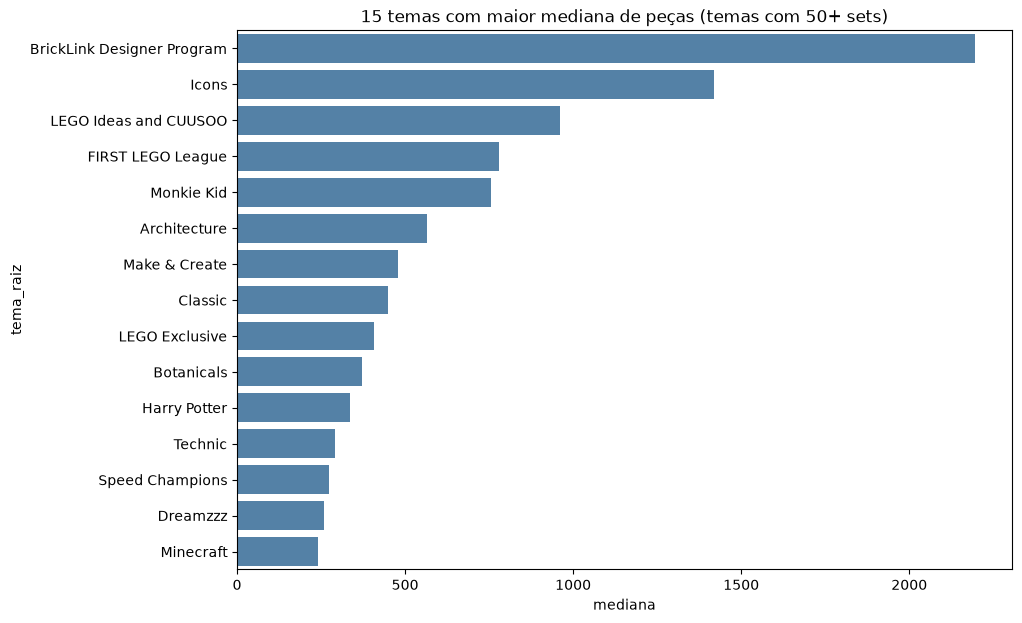

In [31]:
plt.figure(figsize=(10,7))
sns.barplot(data=temas_pecas.head(15), y='tema_raiz', x='mediana', color='steelblue')
plt.title('15 temas com maior mediana de peças (temas com 50+ sets)')
plt.show()

In [32]:
# maiores sets de todos
spark.sql('''
select year, name, tema_raiz, num_parts
from montaveis order by num_parts desc limit 10
''').show(truncate=False)

+----+-----------------------------------+----------------+---------+
|year|name                               |tema_raiz       |num_parts|
+----+-----------------------------------+----------------+---------+
|2021|World Map                          |LEGO Art        |11695    |
|2015|The Ultimate Battle for Chima      |Legends of Chima|10001    |
|2022|Eiffel Tower                       |Icons           |10001    |
|2021|Titanic                            |Icons           |9092     |
|2020|Colosseum                          |Icons           |9036     |
|2025|Death Star                         |Star Wars       |9031     |
|2026|The Lord of the Rings: Minas Tirith|Icons           |8278     |
|2017|Millennium Falcon                  |Star Wars       |7541     |
|2026|Venusaur, Charizard and Blastoise  |Pokémon         |6838     |
|2021|AT-AT                              |Star Wars       |6785     |
+----+-----------------------------------+----------------+---------+



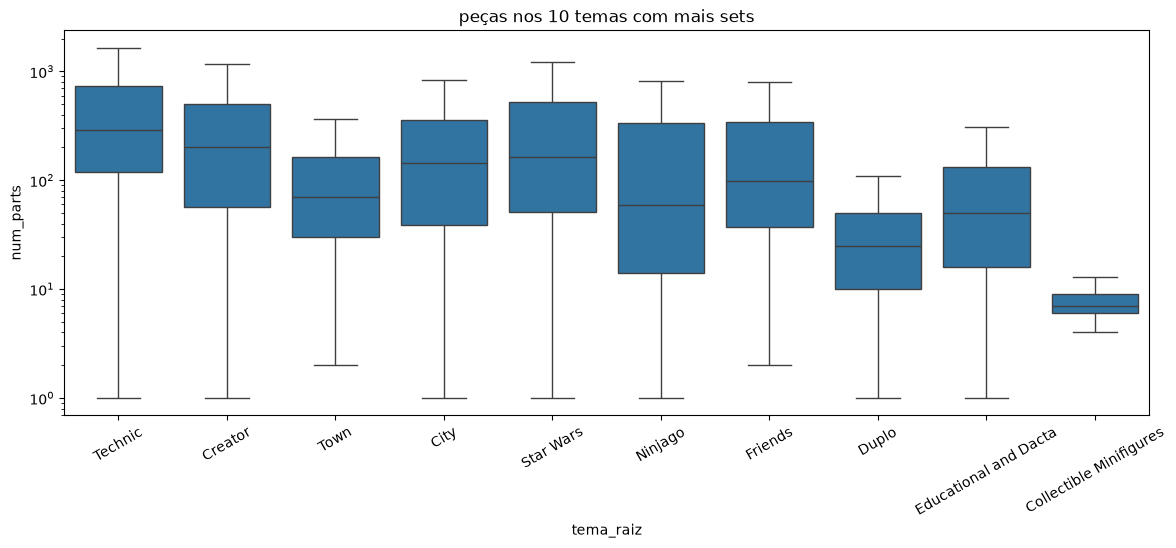

In [33]:
# boxplot dos temas mais populares
populares = pecas['tema_raiz'].value_counts().head(10).index
plt.figure(figsize=(14,5))
sns.boxplot(data=pecas[pecas.tema_raiz.isin(populares)], x='tema_raiz', y='num_parts', showfliers=False)
plt.yscale('log')
plt.xticks(rotation=30)
plt.title('peças nos 10 temas com mais sets')
plt.show()

Os temas com sets maiores são os voltados pra adulto/colecionador: **BrickLink Designer Program** (mediana de 2.196 peças), **Icons** (1.420), **Ideas** (962) e **Architecture** (565). Dos licenciados o maior é Harry Potter (337).

Os maiores sets de todos são o World Map (11.695 peças), a Torre Eiffel, o Titanic e o Coliseu. Tem bastante set recente no top 10, tipo a Death Star de 2025 e o Minas Tirith de 2026.

No boxplot dos temas mais populares, Technic e Star Wars são os maiores, e Duplo e Collectible Minifigures os menores (faz sentido, Duplo é pra criança pequena e as minifigs vem em saquinho).

### Q4 - Cores

In [34]:
cores = spark.sql('''
select cor, rgb, sum(quantity) as qtd
from wide
group by cor, rgb
order by qtd desc
''').toPandas()

cores['pct'] = cores['qtd'] / cores['qtd'].sum() * 100
print('cores diferentes usadas:', len(cores))
cores.head(15)

cores diferentes usadas: 270


,cor,rgb,qtd,pct
0,Black,05131D,822175,18.035192
1,Light Bluish Gray,A0A5A9,520308,11.413452
2,White,FFFFFF,506504,11.110648
3,Dark Bluish Gray,6C6E68,372549,8.172217
4,Red,C91A09,314825,6.905986
5,Blue,0055BF,202341,4.438543
6,Yellow,F2CD37,201246,4.414523
7,Tan,E4CD9E,196621,4.313069
8,Reddish Brown,582A12,177783,3.899840
9,Green,237841,90853,1.992947


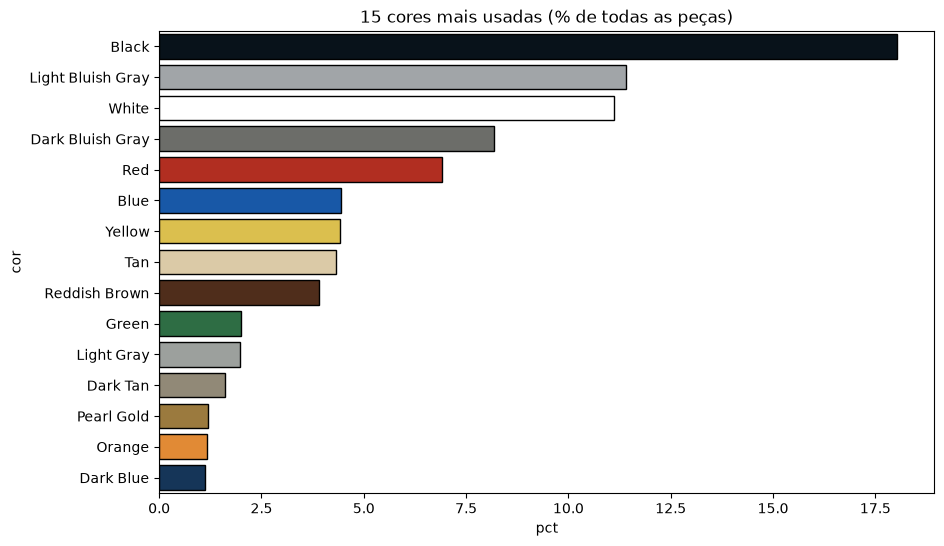

top 5 cores somam 55.6 % das peças


In [35]:
top15 = cores.head(15)
plt.figure(figsize=(10,6))
# usando a cor de verdade de cada peça no grafico :)
sns.barplot(data=top15, y='cor', x='pct', palette=['#' + c for c in top15['rgb']], edgecolor='black')
plt.title('15 cores mais usadas (% de todas as peças)')
plt.show()
print('top 5 cores somam', round(top15['pct'].head(5).sum(), 1), '% das peças')

Agora quantas cores diferentes a lego usou em cada ano

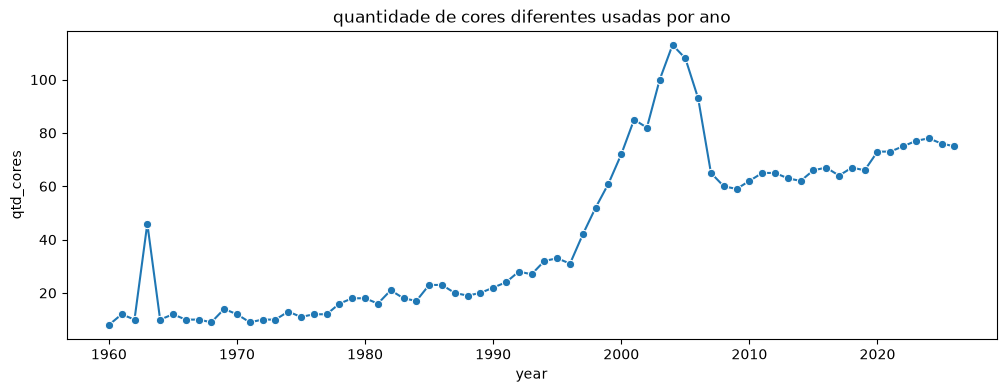

,year,qtd_cores
10,1970,12
20,1980,18
30,1990,22
40,2000,72
44,2004,113
50,2010,62
60,2020,73
66,2026,75


In [36]:
cores_ano = spark.sql('''
select year, count(distinct cor) as qtd_cores
from wide
where year >= 1960
group by year order by year
''').toPandas()

plt.figure(figsize=(12,4))
sns.lineplot(data=cores_ano, x='year', y='qtd_cores', marker='o')
plt.title('quantidade de cores diferentes usadas por ano')
plt.show()
cores_ano[cores_ano.year.isin([1970, 1980, 1990, 2000, 2004, 2010, 2020, 2026])]

Lendo sobre lego descobri que em 2004 a lego trocou o cinza antigo (Light Gray / Dark Gray) por um cinza "azulado" (Light Bluish Gray / Dark Bluish Gray). Será que dá pra ver isso nos dados?

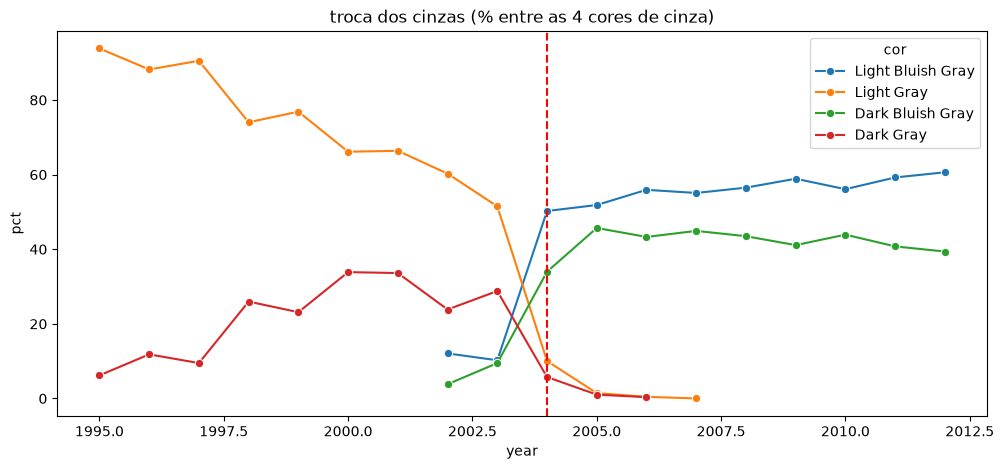

In [37]:
cinzas = spark.sql('''
select year, cor, sum(quantity) as qtd
from wide
where cor in ('Light Gray', 'Dark Gray', 'Light Bluish Gray', 'Dark Bluish Gray') and year between 1995 and 2012
group by year, cor
''').toPandas()

tot = cinzas.groupby('year')['qtd'].transform('sum')
cinzas['pct'] = cinzas['qtd'] / tot * 100

plt.figure(figsize=(12,5))
sns.lineplot(data=cinzas, x='year', y='pct', hue='cor', marker='o')
plt.axvline(2004, color='red', linestyle='--')
plt.title('troca dos cinzas (% entre as 4 cores de cinza)')
plt.show()

- A lego usou 270 cores diferentes no total, mas **as 5 primeiras (preto, cinza claro, branco, cinza escuro e vermelho) somam 55% de todas as peças**. O preto sozinho é 18%.
- O número de cores diferentes por ano subiu de 12 (1970) e 22 (1990) até um pico de **113 cores em 2004**, e depois caiu pra uns 60 em 2010. Hoje está em uns 75. Lendo sobre isso, a lego quase faliu em 2003-2004 e uma das coisas que fez foi cortar um monte de cores pra baratear a produção. Dá pra ver isso direitinho no gráfico!
- **A troca dos cinzas aparece muito bem nos dados:** até 2003 quase todo cinza era o Light Gray antigo, e a partir de 2004 o Light Bluish Gray e o Dark Bluish Gray tomam conta. Em 2005 os cinzas antigos praticamente sumiram.

### Q5 - Cores características de cada tema

Pra cada tema calculei o % de cada cor e comparei com o % geral (tipo um "lift"): se der 3, a cor aparece 3x mais naquele tema do que na média.

In [38]:
temas_q5 = ['Star Wars', 'City', 'Friends', 'Ninjago', 'Technic', 'Duplo', 'Bionicle', 'Super Heroes Marvel']

cor_tema = spark.sql('''
select tema_raiz, cor, rgb, sum(quantity) as qtd
from wide
group by tema_raiz, cor, rgb
''').toPandas()

cor_tema['pct_tema'] = cor_tema['qtd'] / cor_tema.groupby('tema_raiz')['qtd'].transform('sum') * 100
geral = cor_tema.groupby('cor')['qtd'].sum() / cor_tema['qtd'].sum() * 100
cor_tema['pct_geral'] = cor_tema['cor'].map(geral)
cor_tema['lift'] = cor_tema['pct_tema'] / cor_tema['pct_geral']

# so cores com pelo menos 2% do tema pra nao pegar cor rara
caract = (cor_tema[cor_tema.tema_raiz.isin(temas_q5) & (cor_tema.pct_tema >= 2)]
          .sort_values('lift', ascending=False)
          .groupby('tema_raiz').head(3)
          .sort_values(['tema_raiz', 'lift'], ascending=[True, False]))
caract[['tema_raiz', 'cor', 'pct_tema', 'pct_geral', 'lift']].round(2)

,tema_raiz,cor,pct_tema,pct_geral,lift
6447,Bionicle,Pearl Light Gray,7.59,0.12,65.56
4433,Bionicle,Dark Gray,3.36,0.46,7.24
4324,Bionicle,Dark Red,2.52,1.07,2.35
6160,City,Orange,2.15,1.18,1.83
3325,City,Dark Bluish Gray,12.20,8.17,1.49
4862,City,Light Bluish Gray,14.58,11.41,1.28
1664,Duplo,Bright Green,4.52,0.62,7.34
4879,Duplo,Green,7.23,1.99,3.63
3627,Duplo,Yellow,15.69,4.41,3.55
2762,Friends,Magenta,2.28,0.30,7.60


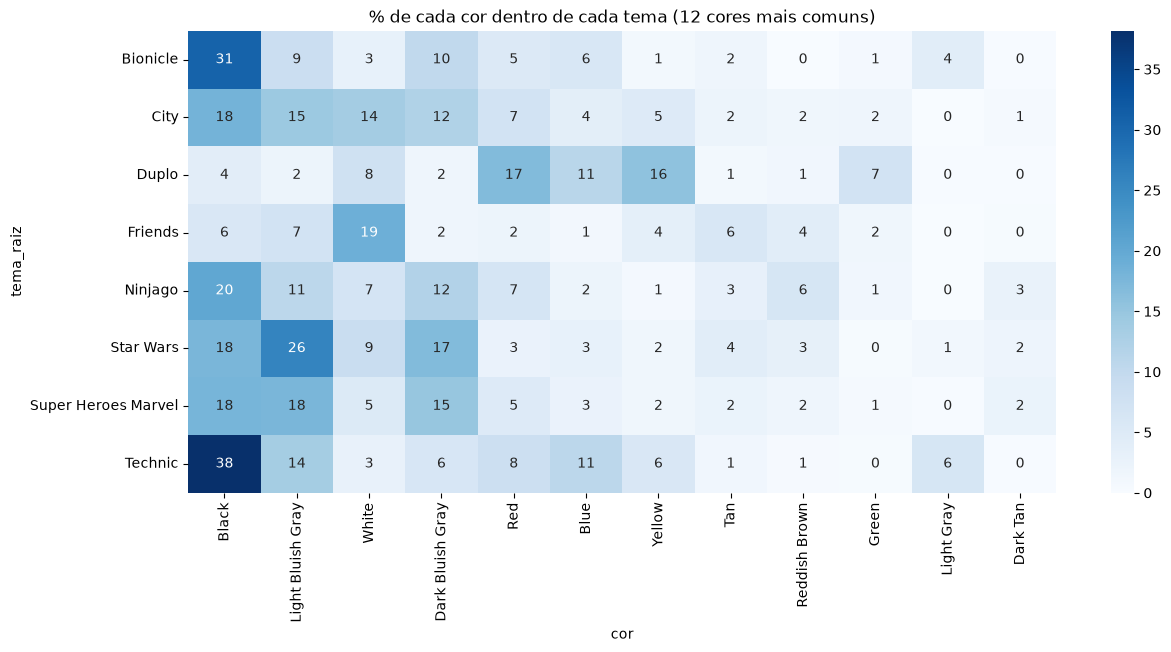

In [39]:
top_cores_lista = cores.head(12)['cor'].tolist()
mapa = (cor_tema[cor_tema.tema_raiz.isin(temas_q5) & cor_tema.cor.isin(top_cores_lista)]
        .pivot(index='tema_raiz', columns='cor', values='pct_tema').fillna(0)[top_cores_lista])

plt.figure(figsize=(14,6))
sns.heatmap(mapa, annot=True, fmt='.0f', cmap='Blues')
plt.title('% de cada cor dentro de cada tema (12 cores mais comuns)')
plt.show()

Sim, cada tema tem cores bem características:
- **Star Wars**: cinza! Light Bluish Gray (26%) + Dark Bluish Gray (17%) = 43% das peças, o dobro da média. Faz sentido, naves e Império.
- **Friends**: Magenta, Dark Pink e Medium Azure aparecem 5 a 7x mais que na média. Também tem muito branco (19%).
- **Duplo**: amarelo (16%), verde e verde claro. Cores primárias de criança.
- **Ninjago**: Pearl Gold (dourado) aparece 5x mais que a média.
- **Marvel**: Dark Red (Homem de Ferro?) e Dark Blue.
- **Technic**: preto (38% das peças!) e azul. E o Light Gray antigo, porque o Technic é um tema antigo.
- **Bionicle**: Pearl Light Gray aparece 65x mais que a média, é praticamente uma cor só do Bionicle.
- **City** é o mais "normal", as cores dele são parecidas com a média geral.

### Q6 - Categorias de peças e minifigs

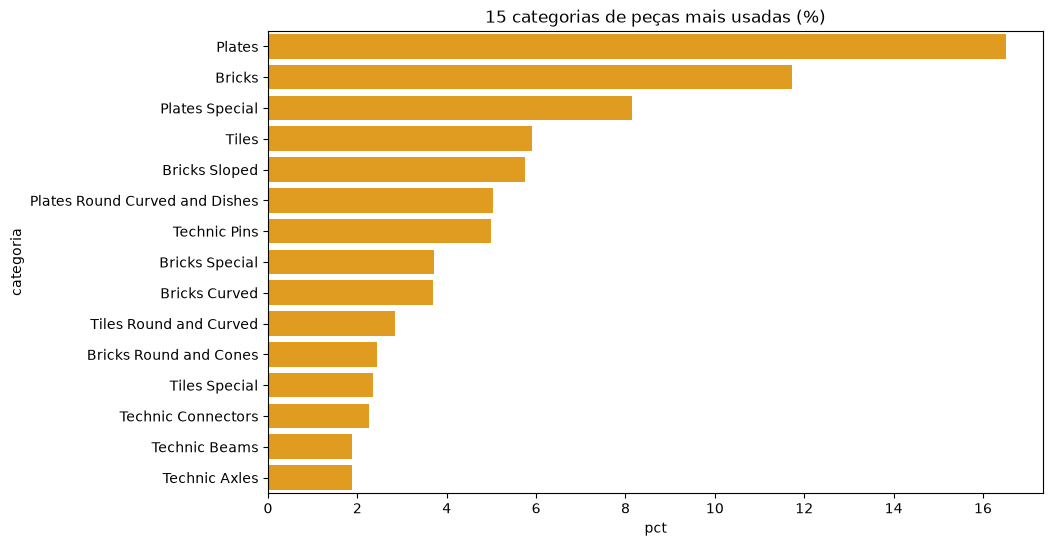

,categoria,qtd,pecas_diferentes,pct
0,Plates,752938,127,16.516413
1,Bricks,534441,1677,11.723473
2,Plates Special,371208,495,8.142801
3,Tiles,268912,3579,5.898841
4,Bricks Sloped,262658,548,5.761654
5,Plates Round Curved and Dishes,229684,369,5.038337
6,Technic Pins,227108,34,4.981830
7,Bricks Special,169097,271,3.709304
8,Bricks Curved,168048,874,3.686293
9,Tiles Round and Curved,129138,1250,2.832765


In [40]:
cat = spark.sql('''
select categoria, sum(quantity) as qtd, count(distinct part_num) as pecas_diferentes
from wide
group by categoria order by qtd desc
''').toPandas()
cat['pct'] = cat['qtd'] / cat['qtd'].sum() * 100

plt.figure(figsize=(10,6))
sns.barplot(data=cat.head(15), y='categoria', x='pct', color='orange')
plt.title('15 categorias de peças mais usadas (%)')
plt.show()
cat.head(10)

In [41]:
# peças que aparecem em mais sets
spark.sql('''
select w.part_num, p.name, count(distinct w.set_num) as qtd_sets
from wide w join parts p on w.part_num = p.part_num
group by w.part_num, p.name
order by qtd_sets desc limit 10
''').show(truncate=False)

+--------+---------------------------------+--------+
|part_num|name                             |qtd_sets|
+--------+---------------------------------+--------+
|3023    |Plate 1 x 2                      |9005    |
|3020    |Plate 2 x 4                      |7879    |
|3022    |Plate 2 x 2                      |7703    |
|6141    |Plate Round 1 x 1 with Solid Stud|7407    |
|3710    |Plate 1 x 4                      |7066    |
|3004    |Brick 1 x 2                      |6762    |
|3021    |Plate 2 x 3                      |6503    |
|3069b   |Tile 1 x 2 with Groove           |5809    |
|3795    |Plate 2 x 6                      |5717    |
|3024    |Plate 1 x 1                      |5480    |
+--------+---------------------------------+--------+



In [42]:
# quantas peças só aparecem em 1 set?
spark.sql('''
select sum(case when n = 1 then 1 else 0 end) as pecas_exclusivas, count(*) as total_pecas,
       round(sum(case when n = 1 then 1 else 0 end) / count(*) * 100, 1) as pct
from (select part_num, count(distinct set_num) as n from wide group by part_num)
''').show()

+----------------+-----------+----+
|pecas_exclusivas|total_pecas| pct|
+----------------+-----------+----+
|           26743|      41447|64.5|
+----------------+-----------+----+



Agora minifigs: quantas minifigs vem por set ao longo do tempo (só sets que tem minifig)

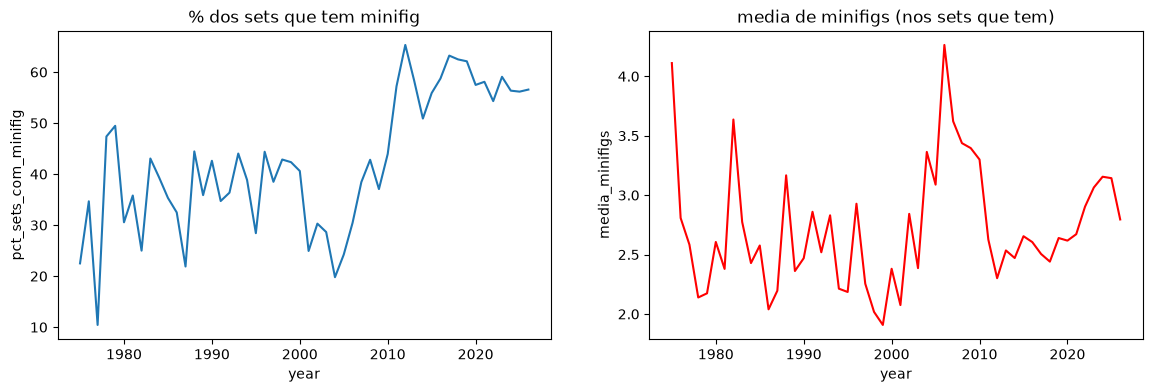

,year,sets_com_minifig,media_minifigs,total_sets,pct_sets_com_minifig
5,1980,33,2.61,108,30.56
15,1990,49,2.47,115,42.61
25,2000,134,2.38,330,40.61
35,2010,167,3.30,380,43.95
45,2020,392,2.62,682,57.48
51,2026,435,2.80,769,56.57


In [43]:
minifig_ano = spark.sql('''
select m.year, count(distinct m.set_num) as sets_com_minifig, avg(x.qtd_minifig) as media_minifigs
from montaveis m
join inventories i on m.set_num = i.set_num and i.version = 1
join (select inventory_id, sum(quantity) as qtd_minifig from inventory_minifigs group by inventory_id) x
     on x.inventory_id = i.id
where m.year >= 1975
group by m.year order by m.year
''').toPandas()

total_ano = pecas.groupby('year').size().rename('total_sets')
minifig_ano = minifig_ano.join(total_ano, on='year')
minifig_ano['pct_sets_com_minifig'] = minifig_ano['sets_com_minifig'] / minifig_ano['total_sets'] * 100

fig, ax = plt.subplots(1, 2, figsize=(14,4))
sns.lineplot(data=minifig_ano, x='year', y='pct_sets_com_minifig', ax=ax[0])
ax[0].set_title('% dos sets que tem minifig')
sns.lineplot(data=minifig_ano, x='year', y='media_minifigs', ax=ax[1], color='red')
ax[1].set_title('media de minifigs (nos sets que tem)')
plt.show()
minifig_ano[minifig_ano.year.isin([1980, 1990, 2000, 2010, 2020, 2026])].round(2)

- As categorias mais usadas são **Plates** (16,5% das peças), **Bricks** (11,7%) e Plates Special (8%). O tijolo clássico não é a peça mais usada, a placa é!
- A peça que aparece em mais sets é a **Plate 1 x 2** (em 9.005 sets), seguida de outras placas.
- Technic Pins são 5% de todas as peças mas só existem 34 tipos diferentes.
- Curioso: **64,5% dos tipos de peça aparecem em só 1 set**. Ou seja, tem um monte de peça exclusiva (adesivos, peças impressas etc).

Minifigs: até 2010 uns 30-45% dos sets tinham minifig, e a partir de 2012 mais ou menos passou pra uns 55-60%. Mas a quantidade de minifigs por set (nos que tem) ficou parecida, entre 2,5 e 3.

### Resumo do EXPLORE


- os lançamentos aumentaram muito (1.555 sets em 2026)
- os sets ficaram maiores, principalmente depois de 2020
- temas de adulto (Icons, Ideas, BrickLink) tem os maiores sets
- poucas cores dominam (top 5 = 55%), e a lego cortou muitas cores depois de 2004 e trocou os cinzas
- cada tema tem um "DNA" de cores (Star Wars cinza, Friends rosa/azul, Ninjago dourado)
- placas são as peças mais usadas e mais da metade dos tipos de peça são exclusivos de um set

## 4. MODEL - Descobrir o tema pelo "DNA" do set (Q7)

Ideia: cada set tem uma "receita" de cores e tipos de peça. Será que um modelo consegue adivinhar o tema só por isso?

Vamos usar os 6 temas com mais sets montáveis que são bem diferentes entre si: Star Wars, City, Friends, Ninjago, Technic e Duplo.

Features (tudo calculado no spark):
- % de cada uma das 20 cores mais usadas no set
- % de cada uma das 15 categorias de peça mais usadas
- log do nº de peças e o ano

Modelo: Random Forest (classificação) do MLlib.

In [44]:
from pyspark.ml.feature import StringIndexer, VectorAssembler
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

temas_modelo = ['Star Wars', 'City', 'Friends', 'Ninjago', 'Technic', 'Duplo']
top20_cores = cores.head(20)['cor'].tolist()
top15_cat = cat.head(15)['categoria'].tolist()

base = wide.filter(F.col('tema_raiz').isin(temas_modelo)).filter('num_parts >= 20')
total = base.groupBy('set_num').agg(F.sum('quantity').alias('total'))

# pivot das cores e categorias (cada cor vira uma coluna)
piv_cor = base.groupBy('set_num').pivot('cor', top20_cores).sum('quantity').fillna(0)
piv_cat = base.groupBy('set_num').pivot('categoria', top15_cat).sum('quantity').fillna(0)

info = base.select('set_num', 'tema_raiz', 'year', 'num_parts').distinct()
dados = info.join(total, 'set_num').join(piv_cor, 'set_num').join(piv_cat, 'set_num')

# transformando em % do set
cols_feat = []
for c in top20_cores + top15_cat:
    novo = 'f_' + c.replace(' ', '_').replace(',', '').replace('-', '_').replace('/', '_')
    dados = dados.withColumn(novo, F.col('`' + c + '`') / F.col('total'))
    cols_feat.append(novo)

dados = dados.withColumn('log_pecas', F.log('num_parts'))
cols_feat += ['log_pecas', 'year']

dados = dados.select('set_num', 'tema_raiz', *cols_feat).cache()
print('sets pro modelo:', dados.count())
dados.groupBy('tema_raiz').count().orderBy('count', ascending=False).show()

sets pro modelo: 4204


+---------+-----+
|tema_raiz|count|
+---------+-----+
|Star Wars|  902|
|     City|  824|
|    Duplo|  804|
|  Friends|  628|
|  Technic|  577|
|  Ninjago|  469|
+---------+-----+



In [45]:
indexer = StringIndexer(inputCol='tema_raiz', outputCol='label')
assembler = VectorAssembler(inputCols=cols_feat, outputCol='features')

dados_ml = assembler.transform(indexer.fit(dados).transform(dados))
labels = indexer.fit(dados).labels

treino, teste = dados_ml.randomSplit([0.8, 0.2], seed=42)
print(treino.count(), teste.count())

rf = RandomForestClassifier(labelCol='label', featuresCol='features', numTrees=150, maxDepth=10, seed=42)
modelo = rf.fit(treino)
pred = modelo.transform(teste)

acc = MulticlassClassificationEvaluator(labelCol='label', metricName='accuracy').evaluate(pred)
f1 = MulticlassClassificationEvaluator(labelCol='label', metricName='f1').evaluate(pred)
print('acuracia:', round(acc, 3))
print('f1:', round(f1, 3))

3376 828


acuracia: 0.928
f1: 0.927


In [46]:
# comparando com um "chute": sempre o tema mais comum
mais_comum = treino.groupBy('label').count().orderBy('count', ascending=False).first()['label']
print('acuracia do chute:', round(teste.filter(F.col('label') == mais_comum).count() / teste.count(), 3))

acuracia do chute: 0.22


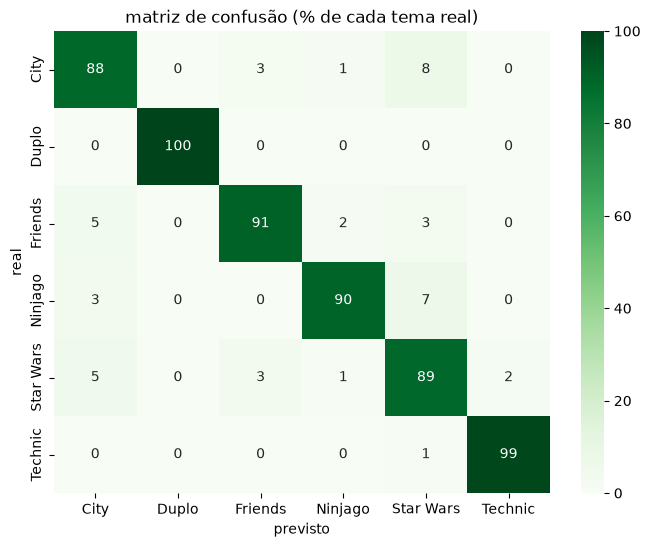

In [47]:
# matriz de confusao
mc = pred.groupBy('label', 'prediction').count().toPandas()
mc['real'] = mc['label'].apply(lambda x: labels[int(x)])
mc['previsto'] = mc['prediction'].apply(lambda x: labels[int(x)])
matriz = mc.pivot(index='real', columns='previsto', values='count').fillna(0)
matriz = matriz.div(matriz.sum(axis=1), axis=0) * 100   # % por linha

plt.figure(figsize=(8,6))
sns.heatmap(matriz, annot=True, fmt='.0f', cmap='Greens')
plt.title('matriz de confusão (% de cada tema real)')
plt.show()

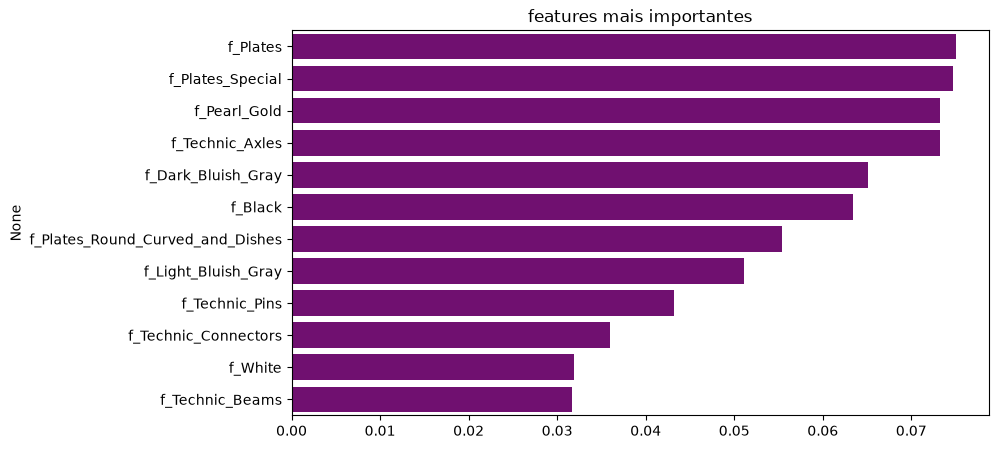

In [48]:
imp = pd.Series(modelo.featureImportances.toArray(), index=cols_feat).sort_values(ascending=False).head(12)
plt.figure(figsize=(9,5))
sns.barplot(x=imp.values, y=imp.index, color='purple')
plt.title('features mais importantes')
plt.show()

O modelo foi **muito melhor do que eu esperava**: acurácia de **92,8%** (F1 de 0,93). Um "chute" sempre no tema mais comum acertaria só 22%.

Pela matriz de confusão:
- **Duplo (100%) e Technic (99%)** quase nunca erram, porque são peças totalmente diferentes (Duplo é peça grande e Technic é pino e eixo)
- Friends (91%), Ninjago (90%), Star Wars (89%) e City (88%) erram um pouco mais
- a maior confusão é **City com Star Wars** (8% dos City foram previstos como Star Wars), provavelmente porque os dois usam muito cinza. Ninjago também confunde com Star Wars (7%)

As features mais importantes foram a % de **Plates**, Plates Special, **Pearl Gold** (o dourado do Ninjago), Technic Axles e os cinzas. Bate com o que vimos na Q5.

Então respondendo a Q7: **sim, dá pra descobrir o tema de um set só pelas cores e tipos de peça**, pelo menos entre esses 6 temas.

O que faltou: testar com mais temas (com temas parecidos tipo City e Town deve errar bem mais) e ajustar os parâmetros com cross validation.

## 5. COMMUNICATE - Conclusões


Respondendo as perguntas:

1. **Lançamentos:** cresceram muito, de 110 sets em 1980 pra 1.555 em 2026. E muita coisa nova nem é de montar (Gear, livros).
2. **Complexidade:** os sets ficaram maiores, a mediana foi de ~50 peças pra 245 em 2026, e acelerou depois de 2020.
3. **Temas:** os maiores são os de adulto (BrickLink Designer Program, Icons, Ideas, Architecture).
4. **Cores:** 5 cores são mais da metade das peças. A quantidade de cores chegou a 113 em 2004 e depois a lego cortou pra uns 60. E dá pra ver a troca dos cinzas em 2004.
5. **Cores por tema:** cada tema tem sua cara: Star Wars cinza, Friends rosa/magenta/azul, Duplo amarelo/verde, Ninjago dourado, Technic preto.
6. **Peças e minifigs:** placas são as peças mais usadas, 64% dos tipos de peça só aparecem em 1 set, e hoje mais da metade dos sets tem minifig.
7. **Modelo:** um Random Forest do MLlib acertou o tema de 93% dos sets só olhando cores e tipos de peça.

Limitações: usamos só a versão 1 dos inventários, tiramos as peças reserva, e o modelo só testou 6 temas bem diferentes entre si. Os dados de 2026 ainda vão mudar porque o ano não acabou.

Usamos IA (LLM) pra ajudar em partes do código, como a especificação permite.

In [49]:
spark.stop()